# Tutorial: modelling dispersion on a DNA-inspired $\pi$-stacking system with Bayesian quantum phase estimation

In this tutorial, we estimate the energy of the same $\pi$-stacked system as in the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) and [Kvantify-SqDRIFT](pi_stacking_sqdrift_tutorial.ipynb) tutorials, but now with quantum phase estimation (QPE), the textbook algorithm for computing energies on a fault-tolerant quantum computer. We compute the energy along a scan of the distance between the stacked fragments, from the equilibrium geometry to the dissociated limit, and use it to estimate the binding energy of the stacked dimer. The quantum chemistry problem is built with projective embedding. The initial state is prepared on Kvantify's memory-restricted simulator, and the QPE circuits are simulated with a GPU state-vector simulator (NVIDIA cuQuantum).

<div align="center"><img src="images/pi_stacking_image.png" alt="Thymine dimer extracted from the DNA atomistic model PDB 208D" width="450"></div>

**Why is this interesting?** The stacking of neighbouring nucleobases helps stabilize the DNA double helix. Dispersion, which arises from electron correlation, is an important contribution, alongside electrostatics and other interactions. The weak binding in the model studied here (below 1 kcal/mol) tests correlated methods: Hartree-Fock and uncorrected B3LYP miss the long-range dispersion contribution.

**How does QPE work?** QPE does not optimize a wave function. Instead, it applies the time-evolution operator $e^{-iHt}$ to an initial state, controlled by an ancilla qubit, and reads the energy from the phase the state picks up. The result is an eigenvalue of the Hamiltonian, and the probability of obtaining the ground-state energy is the squared overlap between the initial state and the ground state. QPE therefore needs a *good initial state*, and here the variational algorithms come into play: we prepare the initial state with orbital-optimized BEAST-VQE, and let QPE refine its energy. We use the Bayesian variant of QPE (BQPE), which needs a single ancilla qubit and updates a probability distribution of the energy after every measurement, until the uncertainty is below a chosen tolerance.

To keep the circuits small, we use the *paired-electron* (seniority-zero) approximation of the Hamiltonian, in which the electrons are kept in pairs. This is the same approximation that is used by BEAST-VQE, so that each spatial orbital is described by a single qubit and the BEAST-VQE state is a natural initial state for QPE.

**What you will learn:**
- how to reuse the embedded problems shared by the $\pi$-stacking tutorials;
- how to prepare an initial state with BEAST-VQE and refine its energy with Bayesian QPE;
- what the main knobs of QPE are: the Trotterized time evolution and the target uncertainty;
- how to turn the results into a binding curve, and compare QPE with the classical CASCI and CCSD(T) references and with the other quantum algorithms.

This notebook is one of a series of $\pi$-stacking tutorials living in the same folder: the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb), the [Kvantify-SqDRIFT tutorial](pi_stacking_sqdrift_tutorial.ipynb), and this QPE tutorial. They all use exactly the same embedded problems, and the checkpoint files for the default settings are included, so the expensive embedding and active space step does not have to be repeated.

## Requirements and hardware

- **Qrunch:** install `qrunch` following the [installation guide](https://qrunch.docs.kvantify.net/docs/getting_started.html).
- **License:** a [Qrunch Pro license](https://qrunch.docs.kvantify.net/docs/getting_started.html#register-a-license) is required for QPE.
- **Additional package:** `matplotlib` for plotting.
- **Hardware:** 16 GB RAM and a multicore CPU recommended; allow more RAM for the optional CASCI reference. The QPE estimator as set up here requires a compatible NVIDIA GPU with cuQuantum.
- **Runtime:** the embedded problems for the default settings are included as checkpoint files; building them from scratch takes about an hour on a laptop. The 17-qubit QPE circuits are deep, so their simulation is the most expensive step.
- **Storage:** persisted chemistry data in `output` are shared across the three tutorials; energies are saved in `results`.

All of the classes and methods we need will be found in the `qrunch` package. The documentation for the Kvantify Qrunch can be found [here](https://qrunch.docs.kvantify.net/index.html). We also define the folders where files will be stored, and set up the logger, which allows us to keep track of basic information when running the algorithms.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import qrunch as qc

result_path = Path("results")
result_path.mkdir(exist_ok=True, parents=True)

output_path = Path("output")
output_path.mkdir(exist_ok=True, parents=True)

qc.setup_logger(qc.LOGGER_ESSENTIAL)

## Setting up the experiment

The starting point is an .xyz file containing the 17 points of the scan. For the sake of execution time, we only use 7 of them: two points on the repulsive side, the minimum (scan point 2), three points on the attractive side and the dissociated limit (scan point 16). This subselection is the reason for a bit more complicated code in the experiment setup - otherwise we would just pass the xyz file name to `qc.build_reaction_configuration`.

This problem definition is shared across the $\pi$-stacking tutorials. Building it takes about an hour on a standard laptop, but the checkpoint files for the default settings are included in `output/persister_data`, so you can swiftly move on to the correlated calculation. The choices are explained in more detail in the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb); keep them identical across the tutorials, otherwise the persisted problems are not reused.

In [2]:
reaction_path = Path("submodel_dt6dt7_scan.xyz")
# Normally we would use the reaction_path directly in the build_reaction_configuration step, but here we select specific geometries for the 17-point scan; 2 is the minimum, 16 the dissociated limit.
selected_geometries = [0, 1, 2, 4, 6, 9, 16]

def read_xyz_frames(xyz_path: Path) -> list[list[tuple[str, float, float, float]]]:
    """Return the atoms (element, x, y, z) of every frame of a multi-frame .xyz file."""
    lines = xyz_path.read_text().strip().splitlines()
    number_of_atoms = int(lines[0])
    frames = []
    for start in range(0, len(lines), number_of_atoms + 2):
        atom_lines = lines[start + 2 : start + 2 + number_of_atoms]
        frames.append([(element, float(x), float(y), float(z)) for element, x, y, z in map(str.split, atom_lines)])
    return frames

scan_frames = read_xyz_frames(reaction_path)
reaction = [scan_frames[index] for index in selected_geometries]
print(f"Selected scan points {selected_geometries} out of {len(scan_frames)}")

Selected scan points [0, 1, 2, 4, 6, 9, 16] out of 17


Now we build our reaction configuration using [projective embedding theory](https://qrunch.docs.kvantify.net/docs/explanations/projective_embedding.html). To focus the correlated calculation on the stacking region, we treat the embedded region with BEAST-VQE followed by QPE and retain a classical DFT environment. This reduces the quantum problem without discarding the surrounding molecular framework. We specify the embedded atoms, spin difference (number of alpha minus beta electrons), charge and a modest basis set for manageable run times.

The embedded region consists of the two thymine rings, their carbonyl oxygens and ring-bound hydrogens, where we focus the treatment of electron correlation. The methyl groups and sugar-backbone stubs remain in the DFT environment.

In [3]:
bset = "6-31+g"
# Embedded atoms (0-based) of each thymine: ring atoms, carbonyl oxygens and the H atoms on N3 and C6.
ring1 = [2, 3, 4, 5, 6, 7, 8, 10, 24, 25]
ring2 = [12, 13, 14, 15, 16, 17, 18, 20, 27, 28]
embedded_atoms = ring1 + ring2
charge = 0
spin = 0

reaction_config = qc.build_reaction_configuration(
    reaction=reaction,
    basis_set=bset,
    charge=charge,
    spin_difference=spin,
    embedded_atoms=embedded_atoms,
)

## Creating the problem with the problem builder

We use the [fluent build pattern](https://qrunch.docs.kvantify.net/docs/explanations/builder_pattern.html) to construct a `problem_builder_creator`. As in the BEAST-VQE tutorial, we calculate along a `reaction_path` with the `even_handed` approach, so that the active orbital assignment is consistent across all frames of the scan. This is crucial for a smooth potential energy surface.

Before going into details here, let us define a couple of parameters that are required for the quantum calculation and which we may want to play with later, specifically:
- the active space: 16 spatial orbitals with 5 alpha (and 5 beta) electrons. In the paired-electron approximation each spatial orbital becomes a single qubit, so the circuits act on 16 qubits, plus the ancilla qubit of BQPE;
- `shots` and `iterations` for the BEAST-VQE state preparation, as in the BEAST-VQE tutorial. A few iterations are enough to get a good overlap with the ground state; QPE takes care of the rest;
- `qpe_tolerance`: BQPE stops when the uncertainty (standard deviation) of the energy is below this value, here 1 mHa, which is below chemical accuracy (1.6 mHa);
- `max_time_step`: the largest time step of the Trotterized time evolution, which controls the Trotter error.

In [4]:
# (16 spatial orbitals, 10 electrons) active space: 16 qubits in the paired-electron encoding, plus one ancilla.
active_orbitals = 16
active_alpha_electrons = 5
shots = 1000
iterations = 10

qpe_tolerance = 1e-3
max_time_step = 0.1

The choices for the following cell, where we run the fluent builder pattern are:
- a DFT (B3LYP) full-system mean-field calculation;
- an orbital assignment based on the total weight of the atomic orbital contributions;
- MP2 natural orbitals for the embedded region (with a truncation of the virtual space);
- resolution of the identity for the full two-electron repulsion integrals;
- the active space defined above, followed by a conversion to dense integrals (which only happens in the active space).

**Important:** to reuse the orbitals and MP2 calculations that were already performed, every option that determines the stored data (functional, basis set, assignment tolerance, MP2 threshold, auxiliary basis, active space, ...) must be identical to the ones used in the earlier run.

In [5]:
dft_options = qc.options.DftCalculatorOptions(functional="b3lyp")
mp2_options = qc.options.MollerPlesset2CalculatorOptions(virtual_truncation_threshold=1e-6)

persister_path = output_path / "persister_data"
persister_path.mkdir(exist_ok=True, parents=True)

reaction_builder_creator = (
    qc.problem_builder_creator()
    .reaction_path()
    .even_handed()
    .choose_full_system_solver()
    .dft(dft_options)
    .choose_orbital_assigner()
    .total_weight(assignment_tolerance=0.3)
    .choose_embedded_orbital_calculator()
    .moller_plesset_2(mp2_options)
    .choose_repulsion_integral_builder()
    .resolution_of_the_identity(auxiliary_basis="heavy-aug-cc-pvdz-ri")
    .add_problem_modifier()
    .active_space(active_orbitals, active_alpha_electrons)
    .add_problem_modifier()
    .to_dense_integrals()
)

When running calculations on embedded systems, it is useful to store the mean-field results and orbital assignment details so that they can be reused. This is the role of the `data_persister_manager`. We point it to the persister folder shared by all the $\pi$-stacking tutorials, and use `load_policy="fallback"`: the stored files are loaded when present, and generated only if they are missing.

In [6]:
reaction_builder_creator = (
    reaction_builder_creator.choose_data_persister_manager().file_persister(
        directory=persister_path,
        extension=".qdk",
        load_policy="fallback",
        overwriting_policy="overwrite",
    )
)

reaction_builder = reaction_builder_creator.create()

We now build the even-handed reaction path problem for the selected scan points. The checkpoint files for the default 7-point selection are included in `output/persister_data`, so this step only loads them: check the log, which should not report any new DFT or MP2 calculations. If you change `selected_geometries`, for instance to compute the full 17-point curve, the problems have to be built from scratch. This takes about an hour for 7 points, and correspondingly longer for the full scan. The new checkpoint files are shared with the other $\pi$-stacking tutorials, so this work only has to be done once.

In [7]:
reaction_problem = reaction_builder.build_restricted(reaction_config)
print(f"Built {len(reaction_problem.ground_state_problems)} problems for scan points {selected_geometries}")

2026-11-25 04:23:53 [WARNING] (kvantify.qrunch): All occupied molecular orbitals were assigned to the EMBEDDED region.
- assignment_tolerance = 0.300000
- Consider increasing the threshold.

MO index   Embedded weight      Environment weight   Assignment          
0          0.400981             0.599019             Embedded            
1          0.337460             0.662540             Embedded            
2          0.389462             0.610538             Embedded            
3          0.370912             0.629088             Embedded            
4          0.446250             0.553750             Embedded            
5          0.492747             0.507253             Embedded            
6          0.924607             0.075393             Embedded            
7          0.930110             0.069890             Embedded            
8          0.873883             0.126117             Embedded            
9          0.748459             0.251541             Embedded        

2026-11-25 04:23:54 [WARNING] (kvantify.qrunch): At geometry 0 and 1 there is a small difference between the least overlapping local MO included and the most overlapping local MO excluded from the embedded region.It is highly encouraged to add additional geometry points along the reaction coordinate. 
2026-11-25 04:23:54 [WARNING] (kvantify.qrunch): At geometry 1 and 2 there is a small difference between the least overlapping local MO included and the most overlapping local MO excluded from the embedded region.It is highly encouraged to add additional geometry points along the reaction coordinate. 
2026-11-25 04:23:54 [WARNING] (kvantify.qrunch): At geometry 2 and 3 there is a small difference between the least overlapping local MO included and the most overlapping local MO excluded from the embedded region.It is highly encouraged to add additional geometry points along the reaction coordinate. 
2026-11-25 04:23:54 [WARNING] (kvantify.qrunch): At geometry 3 and 4 there is a small diffe

Built 7 problems for scan points [0, 1, 2, 4, 6, 9, 16]


## Preparing the initial state with BEAST-VQE

Adaptive BEAST-VQE grows a circuit by selecting paired-electron excitations and optimizing their gate parameters to lower the energy. Orbital optimization separately adjusts the one-electron basis. Here we use fewer iterations than in the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb) and omit PT2: QPE needs the prepared circuit and the optimized orbitals defining its Hamiltonian, not a perturbative energy correction. The estimator and sampler use the memory-restricted simulator.

In [8]:
estimator = qc.estimator_creator().memory_restricted().with_precise_defaults().create()
sampler = qc.sampler_creator().memory_restricted().with_precise_defaults().create()

beast_calculator = (
    qc.calculator_creator()
    .vqe()
    .iterative_with_orbital_optimization()
    .beast()
    .with_gate_selector_sampler(sampler)
    .with_gate_selector_shots(shots)
    .with_estimator(estimator)
    .with_options(qc.options.IterativeVqeOptions(max_iterations=iterations, force_all_iterations=True))
    .with_orbital_optimizer_estimator(estimator)
    .with_intermittent_orbital_optimizer_options(qc.options.IntermittentOrbitalOptimizerAlgorithmOptions.quick())
    .create()
)

beast_results = beast_calculator.calculate(reaction_problem)

2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 1 / 10: -12.115214387336916
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 2 / 10: -12.126863621278122
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 3 / 10: -12.140363755742623
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 4 / 10: -12.150848101908895
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 5 / 10: -12.165617100372671
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 6 / 10: -12.17303877107419
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 7 / 10: -12.174514717221642
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 8 / 10: -12.17499768518764
2026-11-25 04:23:57 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 9 / 10: -12.175237737457346
2026-11-25 04:23:58 [ESSENTIAL] (kvantify.qrunch): Adaptive VQE iteration: 

## Setting up Bayesian quantum phase estimation

QPE needs the time-evolution operator $e^{-iHt}$ as a circuit. This is the job of the *Hamiltonian encoder*. We use a second-order Suzuki-Trotter product formula, which splits the evolution into short time steps. With the `fixed_time_step` mode, the number of Trotter steps grows with the evolution time requested by BQPE, so that no step is longer than `max_time_step` (and at least `trotter_steps` steps are used). This keeps the Trotter error under control also for the long evolution times needed to reach a small uncertainty. The `hardcore_boson` decomposer turns each Trotter step into gates that act on the paired-electron (hard-core boson) qubits.

In [9]:
hamiltonian_encoder = (
    qc.hamiltonian_encoder_creator()
    .trotterization()
    .suzuki_trotter()
    .with_expansion_order(2)
    .with_options(
        qc.options.TrotterizationHamiltonianEncoderOptions(
            mode="fixed_time_step",
            trotter_steps=3,
            reference_time=1.0,
            max_time_step=max_time_step,
        )
    )
    .create()
)

BQPE repeats short experiments: it evolves the initial state for a time $t$, controlled by the ancilla qubit, and measures the ancilla. Each outcome updates a probability distribution (the posterior) over the possible energies, and the next evolution time is chosen based on the current width of the posterior: the narrower it gets, the longer the evolution. BQPE stops when the standard deviation of the posterior is below `tolerance`, or after `max_number_of_iterations` experiments. The `convergence_rate` controls how aggressively the evolution time is increased.

The estimator evaluates the ancilla expectation values. The long evolution times make the QPE circuits deep, so we simulate them with the `cuquantum_statevector` estimator, a full state-vector simulator running on an NVIDIA GPU. With `with_total_estimator_shots(None)` the expectation values are computed exactly, i.e. without shot noise.

In [10]:
qpe_estimator = qc.estimator_creator().cuquantum_statevector().create()

bqpe_options = qc.options.BayesianQuantumPhaseEstimationOptions(
    convergence_rate=2.0,
    max_number_of_iterations=100,
    tolerance=qpe_tolerance,
)

qpe_calculator = (
    qc.calculator_creator()
    .quantum_phase_estimation()
    .bayesian()
    .paired_electron_approximation()
    .with_estimator(qpe_estimator)
    .with_total_estimator_shots(None)
    .with_options(bqpe_options)
    .with_hamiltonian_encoder(hamiltonian_encoder)
    .create()
)

/home/pe/Software/miniconda3/envs/qrunch-release-test/lib/python3.12/importlib/__init__.py:90: UserWarning: The module 'qrunch.core.license.license' is not part of the public API of 'qrunch'. Its interface may change without notice.
The module was imported from importlib.
  return _bootstrap._gcd_import(name[level:], package, level)


Now the chemistry definitions and the quantum algorithm come together. We pass the BEAST-VQE results to the QPE calculator: for each geometry, its circuit is used as the initial state, and its optimized orbitals define the Hamiltonian. The `qpe_results` object contains the energies together with their uncertainties.

This is the longest step of the tutorial, so it is a good moment for a coffee, or two - this cell takes about 1h to run on a standard GPU, much faster on a top-tier GPU. While you wait, think about this: should the QPE energy be above or below the BEAST-VQE energy it starts from?

In [11]:
qpe_results = qpe_calculator.calculate(reaction_problem, beast_results)

2026-11-25 04:24:01 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.018822203: using 3 dynamic Trotter steps.
2026-11-25 04:24:02 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.021327991: using 3 dynamic Trotter steps.
2026-11-25 04:24:02 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.025239373: using 3 dynamic Trotter steps.
2026-11-25 04:24:02 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.030634994: using 3 dynamic Trotter steps.
2026-11-25 04:24:03 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.037541643: using 3 dynamic Trotter steps.
2026-11-25 04:24:03 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.046487541: using 3 dynamic Trotter steps.
2026-11-25 04:24:03 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.057967582: using 3 dynamic Trotter steps.
2026-11-25 04:24:04 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.072378147: using 3 dynamic Trotter steps.
2026-11-25 04:24:04 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.090400313: using 3 dynamic Trotter steps.
2026-11-25

## Extracting results

We first compare, geometry by geometry, the BEAST-VQE energy and the QPE energy with its uncertainty. Since QPE projects onto an eigenstate of the Hamiltonian, its energy should be (within the uncertainty) below the variational BEAST-VQE energy it started from.

In [12]:
beast_energies = beast_results.total_energies.values
qpe_energies = qpe_results.total_energies.values
qpe_errors = qpe_results.total_energies.errors

print(f"{'Scan point':>10s} {'BEAST-VQE':>15s} {'QPE':>24s}")
for index, scan_point in enumerate(selected_geometries):
    print(f"{scan_point:>10d} {beast_energies[index]:>15.6f} {qpe_energies[index]:>15.6f} ± {qpe_errors[index]:.6f}")

Scan point       BEAST-VQE                      QPE
         0    -1019.743815    -1019.743976 ± 0.000941
         1    -1019.749316    -1019.749584 ± 0.000919
         2    -1019.750010    -1019.750176 ± 0.000901
         4    -1019.749386    -1019.749553 ± 0.000873
         6    -1019.748848    -1019.749015 ± 0.000851
         9    -1019.748299    -1019.748469 ± 0.000828
        16    -1019.748229    -1019.748399 ± 0.000991


To plot the energy profile against a physical coordinate, we use the ring-ring separation of each geometry, defined as the distance between the centroids of the two thymine rings (atoms N1, C2, N3, C4, C5, C6 of each monomer). Since the rings are slipped with respect to each other, this distance is larger than the interplanar distance. The separations have been precomputed for all 17 points of the scan:

In [13]:
# Ring centroid-centroid distance (Å) of each of the 17 points in submodel_dt6dt7_scan.xyz.
ring_ring_separation = [
    4.226, 4.682, 5.145, 5.616, 6.090, 6.569, 7.051, 7.534, 8.020,
    8.508, 8.997, 9.487, 9.978, 10.470, 10.963, 11.456, 11.950,
]

separations = [ring_ring_separation[index] for index in selected_geometries]

## Classical reference calculations

To judge the quantum results, we compare them with two well-established classical methods, applied to the same embedded active space:
- CASCI (complete active space configuration interaction) solves the active space problem exactly, including the broken electron pairs that the paired-electron approximation leaves out. Its cost grows exponentially with the size of the active space; with 16 orbitals and 10 electrons there are about 19 million determinants, which is still feasible on a laptop, but it takes a while.
- CCSD(T) (coupled cluster with singles, doubles and perturbative triples), the "gold standard" of quantum chemistry for weakly correlated systems such as this one. Its cost grows polynomially, so it remains feasible for much larger active spaces, where CASCI is out of reach.

The reference energies are the same for all the $\pi$-stacking tutorials. For the default settings they are precomputed in `results/pi_stacking_classical_16o.json`, so the next cell only loads them. Two settings are checked: the number of active orbitals, which is part of the file name, and the scan points, which are stored in the file. Changing either triggers a new calculation (about 30 minutes for the default 16 orbitals and 7 points), and the new energies are written to the file. Other settings, such as the basis set or the embedded atoms, are *not* checked: if you change them, delete or rename the file first, otherwise the cell loads reference energies for a different problem.

In [14]:
classical_result_file = result_path / f"pi_stacking_classical_{active_orbitals}o.json"
classical_data = json.loads(classical_result_file.read_text()) if classical_result_file.exists() else {}

if classical_data.get("geometry_indices") != selected_geometries:
    classical_calculators = {"CCSD(T)": qc.calculator_creator().coupled_cluster().ccsd_t().create()}
    # CASCI scales exponentially with the active space size; beyond about 16 orbitals rely on CCSD(T) only.
    if active_orbitals <= 16:
        classical_calculators["CASCI"] = qc.calculator_creator().configuration_interaction().standard().create()
    classical_data = {"geometry_indices": selected_geometries}
    for label, classical_calculator in classical_calculators.items():
        classical_data[label] = [float(e) for e in classical_calculator.calculate(reaction_problem).total_energies.values]
    classical_result_file.write_text(json.dumps(classical_data, indent=2))

classical_energies = {label: values for label, values in classical_data.items() if label != "geometry_indices"}

## Binding curve

The total energies are large numbers, while the interesting physics happens in the last few decimals. It is therefore more convenient to look at the energy relative to the dissociated limit, in kcal/mol: the depth of the minimum is the binding energy of the stacked dimer. The QPE uncertainties are shown as error bars.

**Where does the binding come from?** The Hartree-Fock reference energy tells us how much of the binding is due to electron correlation, and the classical CASCI and CCSD(T) curves show what the quantum algorithms should aim for. The results of the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) and [Kvantify-SqDRIFT](pi_stacking_sqdrift_tutorial.ipynb) tutorials are loaded from the `results` folder (precomputed results for the default settings are included) and added to the plot. Keep in mind that the QPE curve describes paired electrons only, while the BEAST-VQE tutorial adds a PT2 correction for the broken pairs, and Kvantify-SqDRIFT, CASCI and CCSD(T) are not restricted to paired electrons. Make a guess before running the cell!

                    Reference (Hartree-Fock): binding energy = 0.00 kcal/mol
                                     CCSD(T): binding energy = -0.77 kcal/mol
                                       CASCI: binding energy = -0.77 kcal/mol
                                        BQPE: binding energy = -1.11 kcal/mol


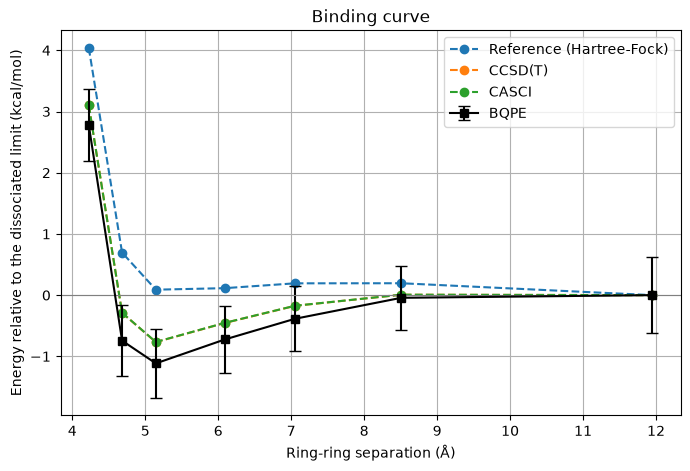

In [15]:
hartree_to_kcal_per_mol = 627.5095

reference_energies = qpe_results.initial_total_energies.values

profiles = {"Reference (Hartree-Fock)": (selected_geometries, reference_energies)}
for label, energies in classical_energies.items():
    profiles[label] = (selected_geometries, energies)

other_tutorials = {
    "OO-BEAST-VQE + PT2 (BEAST tutorial)": f"pi_stacking_beast_{active_orbitals}o.json",
    "Kvantify-SqDRIFT (Kvantify-SqDRIFT tutorial)": f"pi_stacking_sharp_sqdrift_{active_orbitals}o.json",
}
for label, file_name in other_tutorials.items():
    if (result_path / file_name).exists():
        data = json.loads((result_path / file_name).read_text())
        profiles[label] = (data["geometry_indices"], [energy["value"] for energy in data["total_energy_per_geometry"]])

plt.figure(figsize=(8, 5))
for label, (scan_points, energies) in profiles.items():
    # The last scan point is the dissociated limit.
    relative_energies = [(energy - energies[-1]) * hartree_to_kcal_per_mol for energy in energies]
    plt.plot([ring_ring_separation[point] for point in scan_points], relative_energies, marker="o", linestyle="--", label=label)
    print(f"{label:>44s}: binding energy = {min(relative_energies):.2f} kcal/mol")

qpe_relative_energies = [(energy - qpe_energies[-1]) * hartree_to_kcal_per_mol for energy in qpe_energies]
plt.errorbar(
    separations,
    qpe_relative_energies,
    yerr=[error * hartree_to_kcal_per_mol for error in qpe_errors],
    marker="s",
    color="black",
    capsize=4,
    label="BQPE",
)
print(f"{'BQPE':>44s}: binding energy = {min(qpe_relative_energies):.2f} kcal/mol")

plt.axhline(0.0, color="grey", linewidth=0.8)
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy relative to the dissociated limit (kcal/mol)")
plt.title("Binding curve")
plt.legend()
plt.grid()
plt.show()

As in the other tutorials, the Hartree-Fock reference shows no binding: the stacking of the two thymines only appears once electron correlation is included. CASCI, CCSD(T) and Kvantify-SqDRIFT agree on a binding energy of about 0.8 kcal/mol (1.2 mHa), while BQPE and OO-BEAST-VQE + PT2 bind more strongly, by about 1.0-1.1 kcal/mol. This is not an error of QPE: it resolves an eigenvalue of the paired-electron Hamiltonian, which differs from the full electronic-structure Hamiltonian solved by CASCI. The [Kvantify-SqDRIFT tutorial](pi_stacking_sqdrift_tutorial.ipynb) analyses this difference by comparing each method with CASCI.

Note also the size of the QPE error bars. Each energy has an uncertainty just below the tolerance of 1 mHa, and the binding energy combines the uncertainties at two geometries, about 1.3 mHa in total. This is as large as the binding energy itself (about 1.8 mHa for BQPE). Resolving weak interactions with QPE therefore requires a tight tolerance, i.e. long evolution times and deep circuits.

## Saving the results

Finally, we save the results, together with the main parameters of the calculation, to a JSON file. The other $\pi$-stacking tutorials read this file to add the QPE binding curve to their own plots. Note that this overwrites the precomputed results included for the default settings.

In [16]:
final_data = {
    "charge": charge,
    "spin": spin,
    "basis_set": str(bset),
    "embedded_atom_indices": embedded_atoms,
    "cas": {
        "number_of_active_spatial_orbitals": active_orbitals,
        "number_of_active_alpha_electrons": active_alpha_electrons,
    },
    "simulator": {"state_preparation": "memory_restricted", "qpe": "cuquantum_statevector"},
    "state_preparation": {"method": "OO-BEAST-VQE", "number_of_shots": shots, "number_of_iterations": iterations},
    "qpe_tolerance": qpe_tolerance,
    "max_time_step": max_time_step,
    "geometry_indices": selected_geometries,
    "total_energy_per_geometry": [
        {"value": float(value), "error": float(error)} for value, error in zip(qpe_energies, qpe_errors)
    ],
    "reference_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in reference_energies],
    "beast_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in beast_energies],
    "nuclear_repulsion_per_geometry": qpe_results.nuclear_repulsions,
    "non_active_electrons_per_geometry": qpe_results.non_active_electrons_energies,
}

result_name = f"pi_stacking_qpe_{active_orbitals}o.json"
with open(result_path / result_name, "w") as f:
    json.dump(final_data, f, indent=2)
print(f"Saved results to {result_path / result_name}")

Saved results to results/pi_stacking_qpe_16o.json


## Now it's your turn

Some ideas to explore, roughly ordered by the time they take. Keep in mind that rerunning the save cell overwrites the precomputed results that the other $\pi$-stacking tutorials read.
- **Why do we need a good initial state?** Run QPE from the Hartree-Fock state instead, with `qpe_calculator.calculate(reaction_problem.ground_state_problems[2])`, i.e. without the BEAST-VQE result. Which energy do you get, and how does it compare with the QPE energy above? Hint: QPE returns *an* eigenvalue, with a probability given by the overlap of the initial state with the corresponding eigenstate.
- **How good does the initial state need to be?** Lower `iterations` of the BEAST-VQE state preparation to 3 or 5. Does QPE still find the same energy? Does it take longer?
- **Precision versus cost:** tighten `qpe_tolerance` to 0.5 mHa and see how the error bars of the binding curve shrink, and how the runtime grows. Try a single geometry first.
- **Trotter error:** increase `max_time_step` to 0.5. How much do the QPE energies change?
- **Larger active spaces:** with the GPU simulator, larger active spaces (e.g. 20 or 26 orbitals) come within reach. Increase `active_orbitals` (and `active_alpha_electrons` accordingly) and rerun the tutorial. Note that the problems are then built from scratch, and that CASCI is no longer feasible, so CCSD(T) is the only classical reference.
- **The exact paired-electron reference:** CASCI is the exact solution of the electronic-structure Hamiltonian, whose eigenvalues do not depend on the orbital basis. BQPE instead resolves an eigenvalue of the paired-electron (hard-core boson) Hamiltonian, whose eigenvalues do depend on the orbitals. The exact, orbital-optimized solution of this paired-electron problem is computed classically by `qc.calculator_creator().configuration_interaction().paired_with_orbital_optimization().create()`. Run it on `reaction_problem` and add its total energies to the binding-curve plot (before the BQPE curve, so that BQPE stays on top). Do the BQPE energies agree with it within their error bars, and how much of the difference to CASCI is due to the paired-electron approximation? Be patient: this calculation takes a long time.
- **Different scan points:** editing `selected_geometries` changes the problem definition: the problems are built (and persisted) from scratch, which takes about an hour, and the classical reference energies are recomputed and overwrite the included `results/pi_stacking_classical_16o.json`. The results no longer match the precomputed ones of the other $\pi$-stacking tutorials.